# S11 · BI y ML distribuido: KPIs en Pushgateway y modelo en vivo con Grafana

**Equipo 10 · BIG IMPACT · Juliaca**

**Parte A (batch):** KPIs del flujo de eventos calculados sobre el Parquet de observabilidad de S9 y publicados una vez en Pushgateway.

**Parte B (en vivo):** el `PipelineModel` de S10 (RandomForest, sin reentrenar) aplicado sobre `heladas-eventos`, publicando cada predicción en Pushgateway micro-lote por micro-lote.

**Cierre:** tablero de Grafana con paneles batch y en vivo, y verificación con PromQL de que el valor realmente cambia.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
    .appName("sesion11-bi-ml-distribuido")
    .config("spark.sql.shuffle.partitions", "3")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version)

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-e156a276-9c07-4838-830e-7853fbd7c8b6;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.mod

Spark 4.2.0


## 2. KPIs de negocio del flujo de eventos (Parte A, batch)

Se lee el Parquet que dejó S9 (`heladas_eventos_observabilidad`) y se calculan los KPIs que resumen la salud del flujo de eventos de heladas: **volumen**, **ratio de eventos válidos** y **latencia** (promedio y mediana). A diferencia de las métricas de infraestructura (Kafka) y de aplicación (latencia por evento), el ratio de válidos es un KPI de **negocio**: solo se puede calcular con las reglas del dominio (`isValid`).

In [2]:
RUTA_EVENTOS_S9 = "/opt/u2/s09-observabilidad-pipeline/artifacts/heladas_eventos_observabilidad"

eventos = spark.read.parquet(RUTA_EVENTOS_S9)
eventos.printSchema()
print(f"Filas eventos (S9): {eventos.count():,}")

kpi_eventos = eventos.agg(
    F.count("*").alias("total"),
    F.avg(F.col("isValid").cast("int")).alias("ratioValidos"),
    F.avg("latencyMs").alias("avgLatencyMs"),
    F.percentile_approx("latencyMs", 0.5).alias("medianaLatenciaMs"),
    F.max("latencyMs").alias("maxLatenciaMs"),
).first()

print(f"Eventos procesados:     {kpi_eventos['total']:,}")
print(f"Ratio de válidos:       {kpi_eventos['ratioValidos']:.4f}")
print(f"Latencia promedio:      {kpi_eventos['avgLatencyMs']:,.0f} ms")
print(f"Latencia mediana:       {kpi_eventos['medianaLatenciaMs']:,.0f} ms")
print(f"Latencia máxima:        {kpi_eventos['maxLatenciaMs']:,.0f} ms")

root
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- kafkaTimestamp: timestamp (nullable = true)
 |-- tipoEvento: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: double (nullable = true)
 |-- nubosidad: double (nullable = true)
 |-- origen: string (nullable = true)
 |-- observadoEn: long (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- isValid: boolean (nullable = false)
 |-- processedAt: long (nullable = false)
 |-- latencyMs: long (nullable = true)



Filas eventos (S9): 261


[Stage 4:====>                                                    (1 + 11) / 12]

Eventos procesados:     261
Ratio de válidos:       1.0000
Latencia promedio:      92,327 ms
Latencia mediana:       4,362 ms
Latencia máxima:        402,380 ms


## 3. Publicar los KPIs en Pushgateway (una sola vez) y verificarlos en Prometheus

La Parte A calcula números y **termina**: Prometheus (que funciona por *pull*) no podría visitar a un notebook que ya no existe. Por eso el propio notebook **empuja** los valores una vez al Pushgateway (`PUT`), y Prometheus los recoge de ahí en su siguiente *scrape* (15 s). `PUT` reemplaza el grupo completo (`job` + `instance`), que es lo correcto porque cada corrida recalcula el estado completo de los KPIs.

In [3]:
import json
import time
import urllib.request

metricas_flujo = {
    "lambda26_bi_eventos_total": kpi_eventos["total"],
    "lambda26_bi_eventos_validos_ratio": kpi_eventos["ratioValidos"],
    "lambda26_bi_latencia_promedio_ms": kpi_eventos["avgLatencyMs"],
    "lambda26_bi_latencia_mediana_ms": kpi_eventos["medianaLatenciaMs"],
}

lineas = []
for nombre, valor in metricas_flujo.items():
    lineas.append(f"# TYPE {nombre} gauge")
    lineas.append(f"{nombre} {valor}")
cuerpo = "\n".join(lineas) + "\n"

URL_PUSH_FLUJO = "http://pushgateway:9091/metrics/job/lambda26_bi_flujo/instance/s11_batch"
peticion = urllib.request.Request(URL_PUSH_FLUJO, data=cuerpo.encode("utf-8"), method="PUT")
with urllib.request.urlopen(peticion) as r:
    print("Pushgateway respondió:", r.status)

print("Esperando un scrape de Prometheus (20 s)...")
time.sleep(20)

for nombre in metricas_flujo:
    url = f"http://prometheus:9090/api/v1/query?query={nombre}"
    res = json.load(urllib.request.urlopen(url))["data"]["result"]
    print(f"{nombre}: {res[0]['value'][1] if res else 'SIN DATOS'}")

Pushgateway respondió: 200
Esperando un scrape de Prometheus (20 s)...
lambda26_bi_eventos_total: 261
lambda26_bi_eventos_validos_ratio: 1
lambda26_bi_latencia_promedio_ms: 92327.04214559386
lambda26_bi_latencia_mediana_ms: 4362


## 4. Parte B: el modelo de S10, recargado sin reentrenar, sobre el stream de Kafka

Se recarga el `PipelineModel` que guardó S10 (`VectorAssembler` + `RandomForestRegressor`) y se define la lectura en streaming de `heladas-eventos`. Se usa `startingOffsets="latest"`: hoy interesan las lecturas que lleguen a partir de ahora, no el historial. El modelo transforma cada fila tal como llega: sin ventanas, sin watermark y sin estado. Los eventos con campos nulos o fuera de rango se filtran antes del modelo (hallazgo de S10).

In [4]:
from pyspark.ml import PipelineModel
from pyspark.sql.types import (StructType, StructField, StringType,
                               DoubleType, IntegerType, LongType)

RUTA_MODELO_S10 = "/opt/u2/s10-series-tiempo-inferencia-streaming/artifacts/modelo_rf_temp_h1"
modelo_cargado = PipelineModel.load(RUTA_MODELO_S10)
print("Modelo cargado desde:", RUTA_MODELO_S10)

esquema_evento = StructType([
    StructField("tipoEvento", StringType()),
    StructField("ciudad", StringType()),
    StructField("temperatura", DoubleType()),
    StructField("puntoRocio", DoubleType()),
    StructField("humedad", IntegerType()),
    StructField("nubosidad", IntegerType()),
    StructField("origen", StringType()),
    StructField("observadoEn", LongType()),
    StructField("timestamp", LongType()),
])

def preparar(df_kafka):
    ev = (df_kafka
          .select(F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
          .select("e.*")
          .filter(F.col("tipoEvento") == "clima.lectura")
          .dropna(subset=["temperatura", "puntoRocio", "humedad", "nubosidad", "observadoEn"])
          .filter(F.col("temperatura").between(-50, 50))
          .withColumn("observado_utc", (F.col("observadoEn") / 1000).cast("timestamp"))
          .withColumn("hora_local", F.from_utc_timestamp("observado_utc", "America/Lima"))
          .withColumn("hora_dia", F.hour("hora_local"))
          .withColumn("mes", F.month("hora_local")))
    return ev

crudo_stream = (spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "heladas-eventos")
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "false")
    .load())

predicciones_stream = modelo_cargado.transform(preparar(crudo_stream))

print("¿Es un DataFrame de streaming?", predicciones_stream.isStreaming)
predicciones_stream.select("ciudad", "hora_local", "temperatura", "pred_rf").printSchema()

Modelo cargado desde: /opt/u2/s10-series-tiempo-inferencia-streaming/artifacts/modelo_rf_temp_h1
¿Es un DataFrame de streaming? True
root
 |-- ciudad: string (nullable = true)
 |-- hora_local: timestamp (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- pred_rf: double (nullable = false)



## 5. `foreachBatch`: cada micro-lote se guarda en Parquet y se publica en vivo en Pushgateway

Por cada micro-lote, el modelo ya calculó `pred_rf`. La función `foreachBatch` (1) guarda las predicciones en Parquet para BI y (2) empuja al Pushgateway, con `PUT` y `instance=juliaca`, el último valor: temperatura real, predicción a 1 h, alerta de helada, instante del último evento procesado y un contador acumulado de predicciones. Las dos últimas cambian con **cada** lectura, aunque la API repita la temperatura durante la hora.

Nota (atajo documentado en la guía): el Pushgateway está pensado para jobs que terminan; aquí lo usamos para un job continuo por simplicidad. Si el productor se detiene, el último valor queda congelado en el Pushgateway.

In [5]:
RUTA_PRED_STREAM = "./artifacts/predicciones_stream"
CHK_STREAM = "./artifacts/chk_predicciones_stream"
PUSH_BASE = "http://pushgateway:9091/metrics/job/lambda26_ml_streaming/instance"

estado = {"total": 0}

def publicar_en_vivo(instancia, temp_real, pred, alerta, ts_evento):
    cuerpo = (
        "# TYPE lambda26_ml_temperatura_real gauge\n"
        f"lambda26_ml_temperatura_real {temp_real}\n"
        "# TYPE lambda26_ml_prediccion_1h gauge\n"
        f"lambda26_ml_prediccion_1h {pred}\n"
        "# TYPE lambda26_ml_alerta_helada gauge\n"
        f"lambda26_ml_alerta_helada {alerta}\n"
        "# TYPE lambda26_ml_ultimo_evento_ts gauge\n"
        f"lambda26_ml_ultimo_evento_ts {ts_evento}\n"
        "# TYPE lambda26_ml_predicciones_total gauge\n"
        f"lambda26_ml_predicciones_total {estado['total']}\n"
    )
    req = urllib.request.Request(f"{PUSH_BASE}/{instancia}", data=cuerpo.encode("utf-8"), method="PUT")
    urllib.request.urlopen(req).close()

def guardar_y_publicar(df_lote, id_lote):
    filas = df_lote.count()
    if filas == 0:
        print(f"Micro-lote {id_lote}: sin filas")
        return

    (df_lote.select(F.lit(id_lote).alias("batchId"), "ciudad", "observado_utc", "hora_local",
                    "temperatura", "puntoRocio", "humedad", "nubosidad",
                    F.round("pred_rf", 2).alias("temp_pred_1h"),
                    (F.col("pred_rf") <= 0).cast("int").alias("alerta_helada"),
                    F.current_timestamp().alias("procesado_en"))
            .write.mode("append").parquet(RUTA_PRED_STREAM))

    estado["total"] += filas
    ultima = (df_lote.orderBy(F.desc("timestamp")).first())
    publicar_en_vivo(
        ultima["ciudad"].lower(),
        ultima["temperatura"],
        round(ultima["pred_rf"], 2),
        int(ultima["pred_rf"] <= 0),
        ultima["timestamp"] / 1000,
    )
    print(f"Micro-lote {id_lote}: {filas} predicción(es) guardadas y publicadas "
          f"(total acumulado {estado['total']}, última pred {ultima['pred_rf']:.2f} °C)")

consulta_vivo = (predicciones_stream.writeStream
    .foreachBatch(guardar_y_publicar)
    .option("checkpointLocation", CHK_STREAM)
    .queryName("ml_en_vivo")
    .start())

print("Consulta activa:", consulta_vivo.isActive)

26/11/20 11:15:42 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


Consulta activa: True
Micro-lote 0: sin filas


Micro-lote 1: 1 predicción(es) guardadas y publicadas (total acumulado 1, última pred 10.05 °C)


Micro-lote 2: 1 predicción(es) guardadas y publicadas (total acumulado 2, última pred 10.05 °C)


Micro-lote 3: 1 predicción(es) guardadas y publicadas (total acumulado 3, última pred 10.05 °C)


Micro-lote 4: 1 predicción(es) guardadas y publicadas (total acumulado 4, última pred 10.05 °C)


... (10 outputs left out)

Micro-lote 15: 1 predicción(es) guardadas y publicadas (total acumulado 15, última pred 10.05 °C)


Micro-lote 16: 1 predicción(es) guardadas y publicadas (total acumulado 16, última pred 10.05 °C)


Micro-lote 17: 1 predicción(es) guardadas y publicadas (total acumulado 17, última pred 10.05 °C)


Micro-lote 18: 1 predicción(es) guardadas y publicadas (total acumulado 18, última pred 10.05 °C)


## 7. Confirmación en Prometheus: el valor cambia entre una consulta y la siguiente

La misma consulta PromQL se ejecuta dos veces, separadas por más de un `scrape_interval` (15 s). Si las métricas son realmente en vivo, `lambda26_ml_predicciones_total` y `lambda26_ml_ultimo_evento_ts` deben tener un valor **distinto** en la segunda lectura. Se muestran también la temperatura real, la predicción y la alerta.

In [6]:
def consultar(nombre):
    url = f"http://prometheus:9090/api/v1/query?query={nombre}"
    res = json.load(urllib.request.urlopen(url))["data"]["result"]
    return float(res[0]["value"][1]) if res else None

nombres = ["lambda26_ml_predicciones_total", "lambda26_ml_ultimo_evento_ts",
           "lambda26_ml_temperatura_real", "lambda26_ml_prediccion_1h",
           "lambda26_ml_alerta_helada"]

def foto():
    return {n: consultar(n) for n in nombres}

from datetime import datetime
t1 = datetime.now(); a = foto()
print(f"Primera consulta  {t1:%H:%M:%S}:", a)

time.sleep(30)

t2 = datetime.now(); b = foto()
print(f"Segunda consulta  {t2:%H:%M:%S}:", b)

for n in ["lambda26_ml_predicciones_total", "lambda26_ml_ultimo_evento_ts"]:
    print(f"{n}: {a[n]} -> {b[n]}  | cambió: {a[n] != b[n]}")

Primera consulta  11:17:31: {'lambda26_ml_predicciones_total': 15.0, 'lambda26_ml_ultimo_evento_ts': 1795173435.299, 'lambda26_ml_temperatura_real': 10.0, 'lambda26_ml_prediccion_1h': 10.05, 'lambda26_ml_alerta_helada': 0.0}
Micro-lote 19: 1 predicción(es) guardadas y publicadas (total acumulado 19, última pred 10.05 °C)


Micro-lote 20: 1 predicción(es) guardadas y publicadas (total acumulado 20, última pred 10.05 °C)


Micro-lote 21: 1 predicción(es) guardadas y publicadas (total acumulado 21, última pred 10.05 °C)


Micro-lote 22: 1 predicción(es) guardadas y publicadas (total acumulado 22, última pred 10.05 °C)


Micro-lote 23: 1 predicción(es) guardadas y publicadas (total acumulado 23, última pred 10.05 °C)


Micro-lote 24: 1 predicción(es) guardadas y publicadas (total acumulado 24, última pred 10.05 °C)


... (179 outputs left out)

Micro-lote 204: 1 predicción(es) guardadas y publicadas (total acumulado 204, última pred 10.05 °C)


Micro-lote 205: 1 predicción(es) guardadas y publicadas (total acumulado 205, última pred 10.05 °C)


Micro-lote 206: 1 predicción(es) guardadas y publicadas (total acumulado 206, última pred 10.05 °C)


Micro-lote 207: 1 predicción(es) guardadas y publicadas (total acumulado 207, última pred 10.05 °C)


## 8. Métricas del modelo para el tablero: Persistencia vs LinearRegression vs RandomForest

Se publican en Pushgateway (una sola vez, con `PUT`) las métricas de evaluación de S10 sobre el conjunto de prueba (2023-05-26 → 2026-10-01), una serie por modelo mediante la etiqueta `modelo`. Se añade el MAE medido **en vivo** sobre lecturas reales llegadas por Kafka (S10, paso 18). Así el tablero compara los tres modelos y responde "¿qué tan bueno es el modelo?".

In [7]:
tabla_s10 = {
    "Persistencia":     {"rmse": 1.499, "mae": 1.142, "r2": 0.9021, "precision": 0.677, "recall": 0.677, "f1": 0.677},
    "LinearRegression": {"rmse": 1.409, "mae": 1.135, "r2": 0.9134, "precision": 0.723, "recall": 0.336, "f1": 0.459},
    "RandomForest":     {"rmse": 0.971, "mae": 0.730, "r2": 0.9589, "precision": 0.912, "recall": 0.684, "f1": 0.782},
}
mae_en_vivo = {"Persistencia": 0.644, "RandomForest": 0.442}

lineas = []
for metrica in ["rmse", "mae", "r2", "precision", "recall", "f1"]:
    lineas.append(f"# TYPE lambda26_modelo_{metrica} gauge")
    for modelo, vals in tabla_s10.items():
        lineas.append(f'lambda26_modelo_{metrica}{{modelo="{modelo}"}} {vals[metrica]}')
lineas.append("# TYPE lambda26_modelo_mae_vivo gauge")
for modelo, v in mae_en_vivo.items():
    lineas.append(f'lambda26_modelo_mae_vivo{{modelo="{modelo}"}} {v}')
cuerpo = "\n".join(lineas) + "\n"

url = "http://pushgateway:9091/metrics/job/lambda26_ml_modelo/instance/s10_test"
req = urllib.request.Request(url, data=cuerpo.encode("utf-8"), method="PUT")
with urllib.request.urlopen(req) as r:
    print("Pushgateway respondió:", r.status)

time.sleep(20)
res = json.load(urllib.request.urlopen(
    "http://prometheus:9090/api/v1/query?query=lambda26_modelo_f1"))["data"]["result"]
for s in res:
    print(s["metric"]["modelo"], "->", s["value"][1])

Pushgateway respondió: 200


Micro-lote 208: 1 predicción(es) guardadas y publicadas (total acumulado 208, última pred 10.05 °C)


Micro-lote 209: 1 predicción(es) guardadas y publicadas (total acumulado 209, última pred 10.05 °C)


Micro-lote 210: 1 predicción(es) guardadas y publicadas (total acumulado 210, última pred 10.05 °C)


Micro-lote 211: 1 predicción(es) guardadas y publicadas (total acumulado 211, última pred 10.05 °C)


Micro-lote 212: 1 predicción(es) guardadas y publicadas (total acumulado 212, última pred 10.05 °C)


... (3 outputs left out)

Micro-lote 216: 1 predicción(es) guardadas y publicadas (total acumulado 216, última pred 10.05 °C)


Micro-lote 217: 1 predicción(es) guardadas y publicadas (total acumulado 217, última pred 10.05 °C)


Micro-lote 218: 1 predicción(es) guardadas y publicadas (total acumulado 218, última pred 10.05 °C)


Micro-lote 219: 1 predicción(es) guardadas y publicadas (total acumulado 219, última pred 10.05 °C)


## 9. Contexto histórico para el tablero: ¿cuándo hiela en Juliaca?

Se calcula sobre el Gold de U1 (2010 → 2026-10-01, una fila por hora): el **porcentaje de horas con helada (≤ 0 °C) por mes** y el **perfil de temperatura por hora del día** (media y mínima histórica). Se publican en Pushgateway, con una serie por mes (`mes`) y por hora (`hora`), para que el tablero muestre la estacionalidad y el ciclo diario que el modelo aprendió (la hora del día fue su segunda variable más importante).

Micro-lote 220: 1 predicción(es) guardadas y publicadas (total acumulado 220, última pred 10.05 °C)


Micro-lote 221: 1 predicción(es) guardadas y publicadas (total acumulado 221, última pred 10.05 °C)
Horas con helada por mes: {1: 0, 2: 0, 3: 3, 4: 77, 5: 496, 6: 1025, 7: 981, 8: 466, 9: 86, 10: 42, 11: 4, 12: 0}


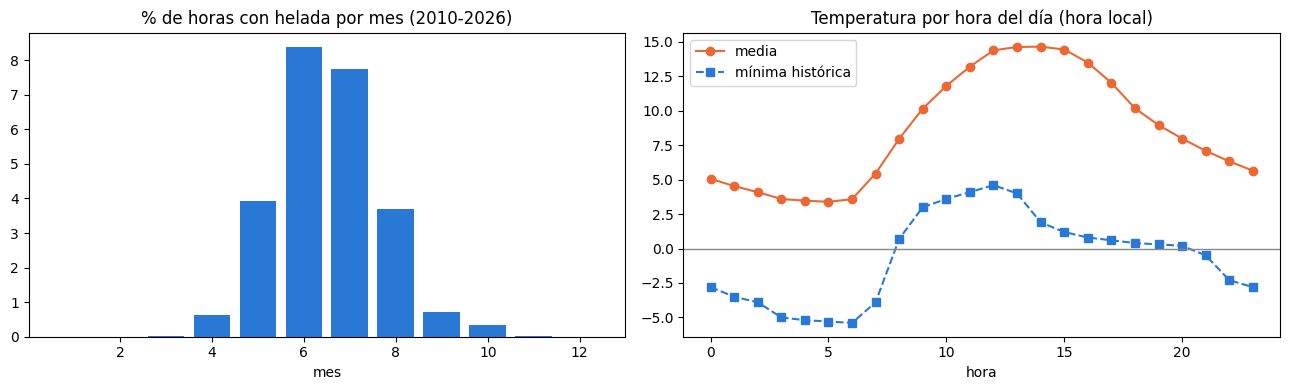

Pushgateway respondió: 200


Micro-lote 222: 1 predicción(es) guardadas y publicadas (total acumulado 222, última pred 10.05 °C)


Micro-lote 223: 1 predicción(es) guardadas y publicadas (total acumulado 223, última pred 10.05 °C)


Micro-lote 224: 1 predicción(es) guardadas y publicadas (total acumulado 224, última pred 10.05 °C)


Micro-lote 225: 1 predicción(es) guardadas y publicadas (total acumulado 225, última pred 10.05 °C)


Micro-lote 226: 1 predicción(es) guardadas y publicadas (total acumulado 226, última pred 10.05 °C)


... (494 outputs left out)

Micro-lote 719: 1 predicción(es) guardadas y publicadas (total acumulado 719, última pred 10.05 °C)


Micro-lote 720: 1 predicción(es) guardadas y publicadas (total acumulado 720, última pred 10.05 °C)


Micro-lote 721: 1 predicción(es) guardadas y publicadas (total acumulado 721, última pred 10.05 °C)


Micro-lote 722: 1 predicción(es) guardadas y publicadas (total acumulado 722, última pred 10.05 °C)


In [8]:
import matplotlib.pyplot as plt

GOLD = "/opt/u1/s03-calidad-particionamiento/artifacts/clima_particionado"
hist = (spark.read.parquet(GOLD)
        .filter(F.col("hora") <= F.lit("2026-10-01 23:59:59").cast("timestamp"))
        .withColumn("mes_n", F.month("hora"))
        .withColumn("hora_n", F.hour("hora")))

por_mes = (hist.groupBy("mes_n")
           .agg((F.avg((F.col("temperatura") <= 0).cast("int")) * 100).alias("pct_helada"),
                F.sum((F.col("temperatura") <= 0).cast("int")).alias("horas_helada"))
           .orderBy("mes_n").collect())

por_hora = (hist.groupBy("hora_n")
            .agg(F.avg("temperatura").alias("t_media"), F.min("temperatura").alias("t_min"))
            .orderBy("hora_n").collect())

print("Horas con helada por mes:", {r["mes_n"]: r["horas_helada"] for r in por_mes})

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar([r["mes_n"] for r in por_mes], [r["pct_helada"] for r in por_mes], color="#2a78d6")
ax[0].set_title("% de horas con helada por mes (2010-2026)"); ax[0].set_xlabel("mes")
ax[1].plot([r["hora_n"] for r in por_hora], [r["t_media"] for r in por_hora], "o-", label="media", color="#eb6834")
ax[1].plot([r["hora_n"] for r in por_hora], [r["t_min"] for r in por_hora], "s--", label="mínima histórica", color="#2a78d6")
ax[1].axhline(0, color="#888780", lw=1); ax[1].legend()
ax[1].set_title("Temperatura por hora del día (hora local)"); ax[1].set_xlabel("hora")
plt.tight_layout(); plt.show()

lineas = ["# TYPE lambda26_hist_helada_pct gauge"]
lineas += [f'lambda26_hist_helada_pct{{mes="{r["mes_n"]:02d}"}} {r["pct_helada"]}' for r in por_mes]
lineas += ["# TYPE lambda26_hist_temp_media gauge"]
lineas += [f'lambda26_hist_temp_media{{hora="{r["hora_n"]:02d}"}} {r["t_media"]}' for r in por_hora]
lineas += ["# TYPE lambda26_hist_temp_min gauge"]
lineas += [f'lambda26_hist_temp_min{{hora="{r["hora_n"]:02d}"}} {r["t_min"]}' for r in por_hora]

req = urllib.request.Request("http://pushgateway:9091/metrics/job/lambda26_bi_historico/instance/gold_u1",
                             data=("\n".join(lineas) + "\n").encode("utf-8"), method="PUT")
with urllib.request.urlopen(req) as r:
    print("Pushgateway respondió:", r.status)

time.sleep(20)
res = json.load(urllib.request.urlopen(
    "http://prometheus:9090/api/v1/query?query=lambda26_hist_helada_pct"))["data"]["result"]
print("Series de heladas por mes en Prometheus:", len(res))

## 10. Auditoría en producción: ¿el modelo acertó con lecturas reales que nunca vio?

Se detiene la consulta en vivo (`ml_en_vivo`) y se juntan las predicciones guardadas por S10 y por S11 (ambas leyeron `heladas-eventos`). Se quitan las lecturas repetidas por `observado_utc` y, para cada predicción a 1 h, se busca la lectura real una hora después. Con esos pares se compara el error del modelo (RandomForest) contra el de la persistencia ("la próxima hora será igual que ahora"), como se hizo en S10 pero con más datos reales de producción.

In [9]:
# 1) Detener la consulta en vivo (el último valor queda congelado en Pushgateway; se limpia después)
consulta_vivo.stop()
print("Consultas activas:", [q.name for q in spark.streams.active])

# 2) Juntar predicciones de S10 y S11 (mismas columnas) y quitar lecturas repetidas
RUTA_PRED_S10 = "/opt/u2/s10-series-tiempo-inferencia-streaming/artifacts/predicciones_heladas"
cols = ["observado_utc", "hora_local", "temperatura", "temp_pred_1h"]

p = (spark.read.parquet(RUTA_PRED_S10).select(*cols)
     .unionByName(spark.read.parquet(RUTA_PRED_STREAM).select(*cols))
     .dropDuplicates(["observado_utc"]))
print("Lecturas distintas con predicción:", p.count())

# 3) Real una hora después de cada predicción
real = p.select((F.col("observado_utc") + F.expr("INTERVAL 1 HOUR")).alias("observado_utc"),
                F.col("temperatura").alias("temp_real_1h"))

cmp = (p.join(real, "observado_utc")
        .withColumn("err_modelo", F.abs(F.col("temp_pred_1h") - F.col("temp_real_1h")))
        .withColumn("err_persist", F.abs(F.col("temperatura") - F.col("temp_real_1h")))
        .orderBy("hora_local"))

cmp.select("hora_local", "temperatura", "temp_pred_1h", "temp_real_1h",
           "err_modelo", "err_persist").show(40, truncate=False)

cmp.agg(F.count("*").alias("pares"),
        F.round(F.avg("err_modelo"), 3).alias("MAE_modelo"),
        F.round(F.avg("err_persist"), 3).alias("MAE_persistencia")).show()

26/11/20 11:59:00 WARN DAGScheduler: Failed to cancel job group 47adf7c1-0222-459c-b733-352cd1d085df. Cannot find active jobs for it.
Exception in thread "stream execution thread for ml_en_vivo [id = aa8bd849-89b4-4e80-a1b6-ae18840014e2, runId = 47adf7c1-0222-459c-b733-352cd1d085df]" java.lang.StackOverflowError
	at java.base/java.util.regex.Pattern$Loop.match(Pattern.java:5074)
	at java.base/java.util.regex.Pattern$GroupTail.match(Pattern.java:5000)
	at java.base/java.util.regex.Pattern$BranchConn.match(Pattern.java:4878)
	at java.base/java.util.regex.Pattern$BmpCharProperty.match(Pattern.java:4134)
	at java.base/java.util.regex.Pattern$Branch.match(Pattern.java:4914)
	at java.base/java.util.regex.Pattern$GroupHead.match(Pattern.java:4969)
	at java.base/java.util.regex.Pattern$Loop.match(Pattern.java:5078)
	at java.base/java.util.regex.Pattern$GroupTail.match(Pattern.java:5000)
	at java.base/java.util.regex.Pattern$BranchConn.match(Pattern.java:4878)
	at java.base/java.util.regex.Patt

Consultas activas: []


Lecturas distintas con predicción: 35


+-------------------+-----------+------------+------------+-------------------+-------------------+
|hora_local         |temperatura|temp_pred_1h|temp_real_1h|err_modelo         |err_persist        |
+-------------------+-----------+------------+------------+-------------------+-------------------+
|2026-11-19 23:15:00|9.2        |8.23        |10.2        |1.9699999999999989 |1.0                |
|2026-11-19 23:30:00|9.2        |8.23        |10.2        |1.9699999999999989 |1.0                |
|2026-11-19 23:45:00|9.2        |8.23        |10.2        |1.9699999999999989 |1.0                |
|2026-11-20 00:00:00|8.1        |7.38        |9.2         |1.8199999999999994 |1.0999999999999996 |
|2026-11-20 00:15:00|8.1        |7.38        |9.2         |1.8199999999999994 |1.0999999999999996 |
|2026-11-20 00:30:00|8.1        |7.38        |9.2         |1.8199999999999994 |1.0999999999999996 |
|2026-11-20 00:45:00|8.1        |7.38        |9.2         |1.8199999999999994 |1.0999999999999996 |


[Stage 3663:=======================================>              (22 + 8) / 30]

+-----+----------+----------------+
|pares|MAE_modelo|MAE_persistencia|
+-----+----------+----------------+
|   31|     1.287|           0.897|
+-----+----------+----------------+



In [11]:
print("Activas:", [q.name for q in spark.streams.active])
if not consulta_vivo.isActive:
    consulta_vivo = (predicciones_stream.writeStream
        .foreachBatch(guardar_y_publicar)
        .option("checkpointLocation", CHK_STREAM)
        .queryName("ml_en_vivo")
        .start())
print("Reanudada:", consulta_vivo.isActive)

Activas: ['ml_en_vivo']
Reanudada: True


Micro-lote 723: 1 predicción(es) guardadas y publicadas (total acumulado 723, última pred 10.05 °C)


Micro-lote 724: 33 predicción(es) guardadas y publicadas (total acumulado 756, última pred 10.05 °C)


Micro-lote 725: 1 predicción(es) guardadas y publicadas (total acumulado 757, última pred 10.05 °C)


Micro-lote 726: 1 predicción(es) guardadas y publicadas (total acumulado 758, última pred 10.05 °C)


Micro-lote 727: 1 predicción(es) guardadas y publicadas (total acumulado 759, última pred 10.05 °C)


Micro-lote 728: 1 predicción(es) guardadas y publicadas (total acumulado 760, última pred 10.05 °C)


Micro-lote 729: 1 predicción(es) guardadas y publicadas (total acumulado 761, última pred 10.05 °C)


Micro-lote 730: 1 predicción(es) guardadas y publicadas (total acumulado 762, última pred 10.05 °C)


Micro-lote 731: 1 predicción(es) guardadas y publicadas (total acumulado 763, última pred 10.05 °C)


Micro-lote 732: 1 predicción(es) guardadas y publicadas (total acumulado 764, última pred 10.05 °C)


## 11. Auditoría justa: una lectura por hora y sesgo del modelo

La API repite cada valor 4 veces por hora (lecturas de 15 min), así que los pares de la auditoría anterior no son independientes. Aquí se conserva una sola lectura por hora (la de :00) y se mide además el **sesgo** (error con signo): un sesgo negativo significa que el modelo predice más frío de lo que ocurre.

In [12]:
cmp_h = (cmp.filter(F.minute("hora_local") == 0)
            .withColumn("sesgo", F.col("temp_pred_1h") - F.col("temp_real_1h")))

cmp_h.select("hora_local", "temperatura", "temp_pred_1h", "temp_real_1h",
             "err_modelo", "err_persist", "sesgo").show(30, truncate=False)

cmp_h.agg(F.count("*").alias("horas"),
          F.round(F.avg("err_modelo"), 3).alias("MAE_modelo"),
          F.round(F.avg("err_persist"), 3).alias("MAE_persistencia"),
          F.round(F.avg("sesgo"), 3).alias("sesgo_modelo")).show()

Micro-lote 733: 1 predicción(es) guardadas y publicadas (total acumulado 765, última pred 10.05 °C)


Micro-lote 734: 1 predicción(es) guardadas y publicadas (total acumulado 766, última pred 10.05 °C)
+-------------------+-----------+------------+------------+-------------------+-------------------+--------------------+
|hora_local         |temperatura|temp_pred_1h|temp_real_1h|err_modelo         |err_persist        |sesgo               |
+-------------------+-----------+------------+------------+-------------------+-------------------+--------------------+
|2026-11-20 00:00:00|8.1        |7.38        |9.2         |1.8199999999999994 |1.0999999999999996 |-1.8199999999999994 |
|2026-11-20 01:00:00|8.1        |7.37        |8.1         |0.7299999999999995 |0.0                |-0.7299999999999995 |
|2026-11-20 02:00:00|7.8        |7.18        |8.1         |0.9199999999999999 |0.2999999999999998 |-0.9199999999999999 |
|2026-11-20 03:00:00|6.9        |6.75        |7.8         |1.0499999999999998 |0.8999999999999995 |-1.0499999999999998 |
|2026-11-20 04:00:00|6.5        |6.49        |6.9    

Micro-lote 735: 4 predicción(es) guardadas y publicadas (total acumulado 770, última pred 10.05 °C)


[Stage 3744:==============================================>       (26 + 4) / 30]

+-----+----------+----------------+------------+
|horas|MAE_modelo|MAE_persistencia|sesgo_modelo|
+-----+----------+----------------+------------+
|    7|     1.217|           0.886|      -0.191|
+-----+----------+----------------+------------+



Micro-lote 736: 4 predicción(es) guardadas y publicadas (total acumulado 774, última pred 10.05 °C)
Micro-lote 737: 1 predicción(es) guardadas y publicadas (total acumulado 775, última pred 10.05 °C)


... (22 outputs left out)

Micro-lote 760: 1 predicción(es) guardadas y publicadas (total acumulado 798, última pred 10.05 °C)


Micro-lote 761: 1 predicción(es) guardadas y publicadas (total acumulado 799, última pred 10.05 °C)


Micro-lote 762: 1 predicción(es) guardadas y publicadas (total acumulado 800, última pred 10.05 °C)


Micro-lote 763: 1 predicción(es) guardadas y publicadas (total acumulado 801, última pred 10.05 °C)


## 12. Hallazgo: en producción, una noche, la persistencia le ganó al RandomForest

| Evaluación | Horas | MAE RandomForest | MAE persistencia |
|---|---|---|---|
| Prueba histórica (S10) | 29 377 | **0.730 °C** | 1.142 °C |
| En vivo, lecturas de Kafka (esta noche) | 7 | 1.217 °C | **0.886 °C** |

**Qué pasó.** El modelo aprendió del histórico que de madrugada la temperatura baja (la hora del día es su segunda variable más importante). Esta noche fue cálida y nublada: la temperatura subió o se mantuvo, el modelo siguió prediciendo enfriamiento y la persistencia ("sigue igual") acertó más. A las 06:00 la temperatura cayó 2.6 °C de golpe y ninguno de los dos lo anticipó (errores de 2.65 y 2.60 °C). El sesgo medio es −0.19 °C: no hay un sesgo sistemático, el modelo falla en ambas direcciones.

**Cómo leerlo.** Son 7 horas de una sola noche, con valores consecutivos muy parecidos, así que no alcanza para decir que el modelo sea peor en general. Lo que sí demuestra es que **el error medido en producción puede diferir del de la prueba histórica**, y que por eso el sistema debe medir su error en vivo en lugar de confiar solo en la evaluación de S10. Con más noches el MAE en vivo se irá estabilizando.

**Decisión.** Se publica en el tablero el MAE en vivo calculado, no el valor escrito a mano de S10.

In [13]:
r = cmp_h.agg(F.avg("err_modelo").alias("m"), F.avg("err_persist").alias("p"),
              F.count("*").alias("n")).first()

cuerpo = (
    "# TYPE lambda26_modelo_mae_vivo gauge\n"
    f'lambda26_modelo_mae_vivo{{modelo="RandomForest"}} {round(r["m"], 3)}\n'
    f'lambda26_modelo_mae_vivo{{modelo="Persistencia"}} {round(r["p"], 3)}\n'
    "# TYPE lambda26_modelo_horas_vivo gauge\n"
    f'lambda26_modelo_horas_vivo {r["n"]}\n'
)
# POST: solo reemplaza estas métricas del grupo; las demás (rmse, f1, ...) no se tocan
url = "http://pushgateway:9091/metrics/job/lambda26_ml_modelo/instance/s10_test"
req = urllib.request.Request(url, data=cuerpo.encode("utf-8"), method="POST")
with urllib.request.urlopen(req) as resp:
    print("Pushgateway respondió:", resp.status)

time.sleep(20)
for q in ["lambda26_modelo_mae_vivo", "lambda26_modelo_f1", "lambda26_modelo_horas_vivo"]:
    res = json.load(urllib.request.urlopen(f"http://prometheus:9090/api/v1/query?query={q}"))["data"]["result"]
    print(q, "->", [(s["metric"].get("modelo", "-"), s["value"][1]) for s in res])

Micro-lote 764: 1 predicción(es) guardadas y publicadas (total acumulado 802, última pred 10.05 °C)


Micro-lote 765: 1 predicción(es) guardadas y publicadas (total acumulado 803, última pred 10.05 °C)
Pushgateway respondió: 200


Micro-lote 766: 4 predicción(es) guardadas y publicadas (total acumulado 807, última pred 10.05 °C)


Micro-lote 767: 1 predicción(es) guardadas y publicadas (total acumulado 808, última pred 10.05 °C)


Micro-lote 768: 1 predicción(es) guardadas y publicadas (total acumulado 809, última pred 10.05 °C)


Micro-lote 769: 1 predicción(es) guardadas y publicadas (total acumulado 810, última pred 10.05 °C)


... (195 outputs left out)

Micro-lote 971: 1 predicción(es) guardadas y publicadas (total acumulado 1012, última pred 12.17 °C)


Micro-lote 972: 1 predicción(es) guardadas y publicadas (total acumulado 1013, última pred 12.17 °C)


Micro-lote 973: 1 predicción(es) guardadas y publicadas (total acumulado 1014, última pred 12.17 °C)


26/11/20 12:50:23 WARN KafkaOffsetReaderAdmin: Error in attempt 1 getting Kafka offsets: 
java.util.concurrent.ExecutionException: org.apache.kafka.common.errors.TimeoutException: Call(callName=listOffsets(api=LIST_OFFSETS), deadlineMs=1795178024074, tries=1, nextAllowedTryMs=1795179023431) timed out at 1795179023351 after 1 attempt(s)
	at java.base/java.util.concurrent.CompletableFuture.reportGet(CompletableFuture.java:396)
	at java.base/java.util.concurrent.CompletableFuture.get(CompletableFuture.java:2073)
	at org.apache.kafka.common.internals.KafkaFutureImpl.get(KafkaFutureImpl.java:165)
	at org.apache.spark.sql.kafka010.KafkaOffsetReaderAdmin.listOffsets(KafkaOffsetReaderAdmin.scala:87)
	at org.apache.spark.sql.kafka010.KafkaOffsetReaderAdmin.$anonfun$fetchLatestOffsets$1(KafkaOffsetReaderAdmin.scala:337)
	at org.apache.spark.sql.kafka010.KafkaOffsetReaderAdmin.$anonfun$partitionsAssignedToAdmin$1(KafkaOffsetReaderAdmin.scala:449)
	at org.apache.spark.sql.kafka010.KafkaOffsetReade

## 13. Cierre: qué se logró en S11 y qué sigue en S12

**Lo que quedó funcionando (y sigue en marcha):**
- **Parte A (batch):** KPIs del flujo de eventos (volumen, ratio de válidos, latencia) calculados sobre el Parquet de S9 y publicados una vez en Pushgateway.
- **Parte B (en vivo):** el `PipelineModel` de S10 sin reentrenar, aplicado sobre `heladas-eventos`. Cada micro-lote guarda su predicción en Parquet y la publica en Pushgateway; Prometheus la recoge cada 15 s y Grafana la muestra. La consulta `ml_en_vivo` queda activa de forma continua.
- **Tablero** `S11 - BI/ML heladas Juliaca` en la carpeta *Proyecto Sello U2*, con la pregunta del proyecto arriba y paneles de riesgo ahora, modelo contra persistencia, flujo e histórico.
- **Prueba de que es en vivo:** el contador `lambda26_ml_predicciones_total` sube entre dos consultas a Prometheus (686 → 698 en un minuto).

**Hallazgo principal:** el RandomForest gana en la prueba histórica (MAE 0.730 °C contra 1.142 °C de la persistencia), pero en las primeras 7 horas en vivo la persistencia tuvo menos error (0.886 contra 1.217 °C). Es una muestra muy corta, y aun así enseña que el error real debe medirse en producción: por eso el tablero muestra el MAE en vivo calculado y no el de la prueba.

**Decisión de diseño documentada (atajo del Pushgateway):** el Pushgateway está pensado para jobs que terminan. Aquí se usa para un job continuo por simplicidad. Mientras el productor y la consulta sigan activos el valor se actualiza; si se detuvieran, el último valor quedaría congelado, y habría que borrar el grupo `lambda26_ml_streaming/instance/juliaca`.

**Conexión con S12 (evaluación de U2):** esta cadena completa (Kafka → Spark Streaming → modelo → Prometheus → Grafana) es la que se sustentará: la pregunta de U2, el modelo comparado contra la persistencia, y la evidencia de que los datos llegan en vivo.